# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [140]:
   
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
                # importar librerías

In [141]:
plans = pd.read_csv("/datasets/plans.csv")         #cargar los datasets nuevamente
user = pd.read_csv("/datasets/users_latam.csv")
usage = pd.read_csv("/datasets/usage.csv")
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [142]:
 plans.head()                     # mostrar las primeras 5 filas de plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [143]:
 user.head()                     # mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [144]:
     usage.head()                # mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [145]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("user", user.shape)
print("usage", usage.shape)

plans (2, 8)
user (4000, 8)
usage (40000, 6)


In [146]:
plans.info()                          # inspección de plans con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [147]:
user.info()                          # inspección de users con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [148]:
usage.info()                       # inspección de usage con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [149]:
print("--- Cantidad de valores nulos ---")
print(user.isna().sum())

--- Cantidad de valores nulos ---
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64


In [150]:
print("\n---Proporcion de valores nulos---")
usage.isna().mean()                        


---Proporcion de valores nulos---


id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- **Las columnas que presentan valores nulos son `city` y `reg_date` (con proporciones menores al 5% cada una). Se debe investiga para imputar o dejar como nulos
- Indica qué harías: ¿imputar, eliminar, ignorar?
- **`city`**: Dejar como nulos o rellenar con un valor desconocido, ya que la proporción es muy baja (<5%) y no afecta drásticamente los cálculos demográficos.
  - **`reg_date`**: Mantener como nulos o eliminar los registros si la fecha de registro es estrictamente indispensable para el análisis de antigüedad.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [151]:
user.describe()            # explorar columnas numéricas de users
# Contar cuántas filas tienen el valor sentinel -999 en age
cantidad_sentinels = (user['age'] == -999).sum()
print("Cantidad de filas con el valor -999:", cantidad_sentinels)

Cantidad de filas con el valor -999: 55


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` ...-
- **La columna `user_id`**: Muestra valores secuenciales y únicos que van desde 10000 hasta 13999, sin anomalías aparentes ni nulos, lo que indica que funciona correctamente como identificador de los 4000 clientes.
- **La columna `age`**: Presenta un valor mínimo de **-999.00**, lo cual es un claro **valor atípico o sentinel (inválido)**, ya que la edad no puede ser negativa. El resto de los valores se distribuyen de forma lógica entre la edad mínima real y un máximo de 79 años, con una mediana de 47.

In [152]:
usage.describe()                 # explorar columnas numéricas de usage

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...
- **Las columnas `id` y `user_id`**: Muestran identificadores secuenciales correctos y coherentes. `id` funciona como el identificador único de cada registro de uso (de 1 a 40,000), mientras que `user_id` vincula cada evento con los usuarios correspondientes (del 10000 al 13999), sin presentar valores nulos ni anomalías.
- **Las columnas `duration` y `length`**: Ambas presentan un valor mínimo de **0.0**, lo cual es lógico ya que puede haber llamadas perdidas o mensajes cortos. La duración de las llamadas alcanza un máximo de 120 minutos, y la longitud de los mensajes llega hasta 1490 caracteres, mostrando distribuciones con presencia de valores altos (posibles outliers). Además, se observa que tienen valores nulos (`count` menor a 40,000), lo cual se debe a que un registro de uso o es una llamada (tiene `duration` y no `length`) o es un mensaje (tiene `length` y no `duration`).

In [153]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(f"---Distribucion de {col}---")
    print(user[col].value_counts(dropna=False))
    print("\n--- Porcentaje de {col} ---")
    print(user[col].value_counts(normalize=True, dropna=False) * 100)
    print("="*40)


---Distribucion de city---
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

--- Porcentaje de {col} ---
Bogotá      20.200
CDMX        18.250
Medellín    15.400
NaN         11.725
GDL         11.250
Cali        10.600
MTY         10.175
?            2.400
Name: city, dtype: float64
---Distribucion de plan---
Basico     2595
Premium    1405
Name: plan, dtype: int64

--- Porcentaje de {col} ---
Basico     64.875
Premium    35.125
Name: plan, dtype: float64


- La columna `city` ...hay datos faltantes
- La columna `plan` ...nos muestra que estan los datos completos, no hay NaN, ? esta limpia

In [154]:
# explorar columna categórica de usage
columnas_usage = ["type", "plan"]
print("---Distribucion de type---")
print(usage['type'].value_counts(dropna=False))
      
print("\n---porcentaje de type---")       # completa el código
print(usage["type"].value_counts(normalize = True, dropna = False) * 100)

---Distribucion de type---
text    22092
call    17908
Name: type, dtype: int64

---porcentaje de type---
text    55.23
call    44.77
Name: type, dtype: float64


- La columna `type` ... los datos estan completos sin ninguna novedad


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels? en users city tiene faltantes(NaN y "?") tanto plan y usage type estan bien 
- ¿Qué acción tomarías? Dejar como valores nulos (pd.NA) y no eliminarlos, Dado que la proporción es moderada (aproximadamente 14%), eliminar estas filas significaría perder una cantidad importante de registros de usuarios, lo cual sesgaría el análisis de uso y comportamiento. Mantenerlos como NaN permite que las bibliotecas de análisis y visualización (como pandas y seaborn) ignoren los datos faltantes automáticamente cuando sea necesario sin alterar el tamaño de la muestra de los clientes.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [155]:
# Convertir a fecha la columna `reg_date` de users
user['reg_date'] = pd.to_datetime(user["reg_date"],errors = "coerce")     # completa el código

In [156]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"], errors = "coerce")   # completa el código

In [157]:
# Revisar los años presentes en `reg_date` de users
user["reg_date"] = pd.to_datetime(user["reg_date"],errors = "coerce")
user["reg_date"].dt.year.value_counts(dropna = False)


2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En `reg_date`, ... haz doble clic en este bloque y escribe qué ves. hay un 1% la cual no afectaria

In [158]:
usage["date"].dt.year.value_counts(dropna = False)        # Revisar los años presentes en `date` de usage


2024.0    39950
NaN          50
Name: date, dtype: int64

En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas. Hay un 1,25% que es muy poco y lo eliminaria

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)año futuro 2026 que es un 1% y el cual se eliminaria
- ¿Qué harías con ellas? se eliminaria ya que es un porcentaje muy pequeño

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [159]:
# Reemplazar -999 por la mediana de age
age_mediana = user.loc[user["age"] !=-999,"age"].median()
user['age'] = user["age"].replace(-999, age_mediana)

# Verificar cambios
user['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [160]:
# Reemplazar ? por NA en city
user["cyti"]=user["city"].replace("?", pd.NA)

# Verificar cambios
print(user["city"].value_counts(dropna=False))


Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64


In [161]:
# Marcar fechas futuras como NA para reg_date
user.loc[user["reg_date"].dt.year>2024, "reg_date"] = pd.NaT

# Verificar cambios
print(user["reg_date"].dt.year.value_counts(dropna=False))


2024.0    1330
2023.0    1316
2022.0    1314
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [162]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby("type")["duration"].apply(lambda x: x.isna().sum())


type
call        0
text    22076
Name: duration, dtype: int64

In [163]:
usage.groupby("type")["length"].apply(lambda x: x.isna().sum())              # Verificación MAR en usage (Missing At Random) para length


type
call    17896
text        0
Name: length, dtype: int64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length Los valores nulos en duration y length siguen un patrón MAR (Missing At Random) ya que su ausencia depende directamente del tipo de evento (type). Específicamente, los nulos en duration ocurren únicamente en los mensajes (text), mientras que los nulos en length ocurren exclusivamente en las llamadas (call). Por lo tanto, se deben mantener como nulos (NaN) y no deben imputarse ni eliminarse, ya que corresponden a la naturaleza propia de cada servicio (los mensajes no tienen duración en minutos y las llamadas no tienen una longitud medida en caracteres).

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [164]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)                  #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int)                 #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({"is_text": "sum","is_call": "sum", "duration": "sum"}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [165]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={"is_text": "cant_mensajes", "is_call": "cant_llamadas", "duration": "cant_minutos_llamada"})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [166]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = user.merge(usage_agg, on="user_id", how="left") 
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cyti,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Medellín,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,?,2022-01-01 06:34:17.914478619,Basico,NaN,<NA>,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,CDMX,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,Bogotá,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,GDL,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [167]:
# Resumen estadístico de las columnas numéricas
columnas_numericas = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
user_profile[columnas_numericas].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [168]:
# Distribución porcentual del tipo de plan
print("---conteo de usuarios por tipo de plan---")
print(user_profile["plan"].value_counts(dropna=False))
print("\n---Porcentaje de usuarios por tipo de plan---")
print(user_profile["plan"].value_counts(normalize=True, dropna=False) * 100)


---conteo de usuarios por tipo de plan---
Basico     2595
Premium    1405
Name: plan, dtype: int64

---Porcentaje de usuarios por tipo de plan---
Basico     64.875
Premium    35.125
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

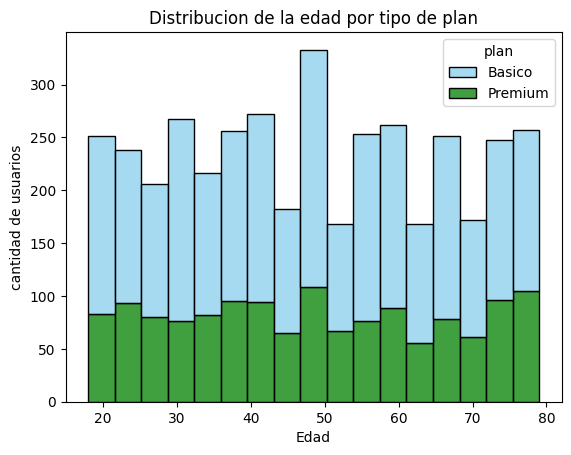

In [169]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x="age",hue="plan",palette=["skyblue", "green"],multiple="stack")
plt.title("Distribucion de la edad por tipo de plan")
plt.xlabel("Edad")
plt.ylabel("cantidad de usuarios")
plt.show()

💡Insights: 
- Distribución ...

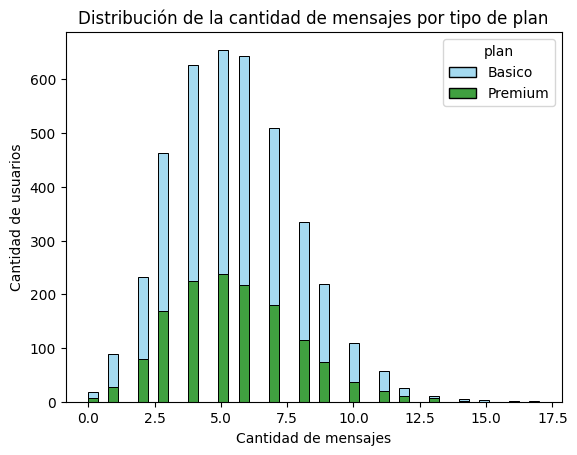

In [170]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x="cant_mensajes", hue="plan", palette=["skyblue", "green"], multiple="stack")
plt.title("Distribución de la cantidad de mensajes por tipo de plan")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Cantidad de usuarios")
plt.show()


💡Insights: Distribución: La distribución de la cantidad de mensajes está sesgada hacia la derecha, concentrando la mayor parte de los usuarios en rangos bajos de mensajes enviados (entre 3 y 7 mensajes), con una caída gradual conforme aumenta la cantidad.

Relación con el plan: La proporción de usuarios con el plan Básico (celeste) y Premium (verde) se mantiene bastante equilibrada en los diferentes niveles de consumo de mensajes, sin que se aprecie que un plan envíe masivamente más mensajes que el otro en los rangos cotidianos.
- ....

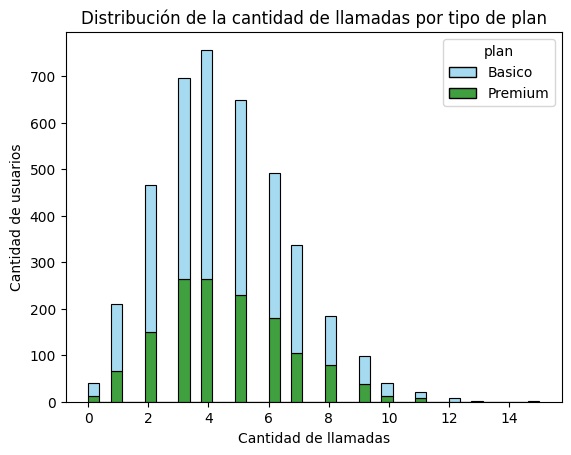

In [171]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x="cant_llamadas", hue="plan", palette=["skyblue", "green"], multiple="stack")
plt.title("Distribución de la cantidad de llamadas por tipo de plan")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Cantidad de usuarios")
plt.show()


💡Insights: Distribución: La distribución de la cantidad de llamadas muestra un sesgo positivo hacia la derecha, concentrando la mayor parte de los usuarios entre 3 y 5 llamadas, con una disminución progresiva a medida que aumenta la frecuencia de llamadas.

Relación con el plan: La proporción entre el plan Básico (celeste) y el Premium (verde) se mantiene constante a lo largo de los diferentes volúmenes de llamadas, lo que indica un comportamiento de consumo similar independientemente del tipo de plan contratado.


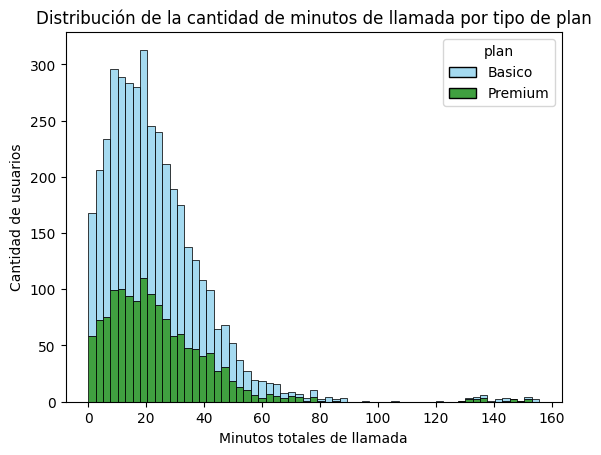

In [172]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x="cant_minutos_llamada", hue="plan", palette=["skyblue", "green"], multiple="stack")
plt.title("Distribución de la cantidad de minutos de llamada por tipo de plan")
plt.xlabel("Minutos totales de llamada")
plt.ylabel("Cantidad de usuarios")
plt.show()


💡Insights: Distribución: La distribución de los minutos consumidos en llamadas está claramente sesgada hacia la derecha, con la mayor concentración de usuarios ubicada en rangos bajos y moderados (principalmente entre 10 y 30 minutos), mientras que una menor proporción de clientes alcanza valores más elevados.

Relación con el plan: La proporción entre los planes Básico (celeste) y Premium (verde) se distribuye de manera uniforme en todos los niveles de consumo en minutos, reflejando que el volumen de llamadas no diferencia de forma drástica el tipo de plan contratado.


### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

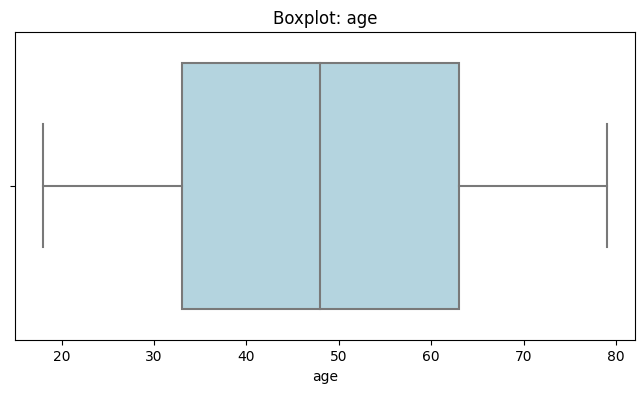

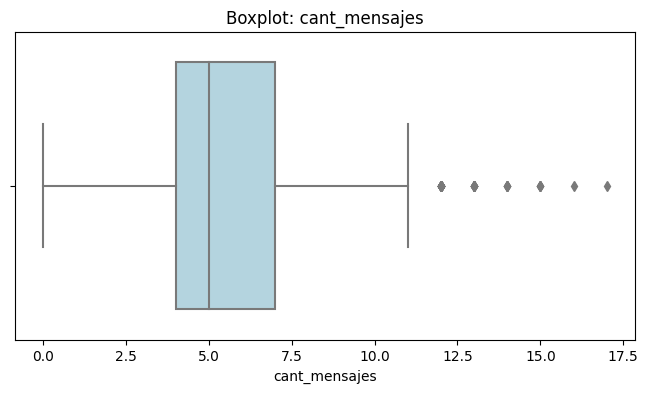

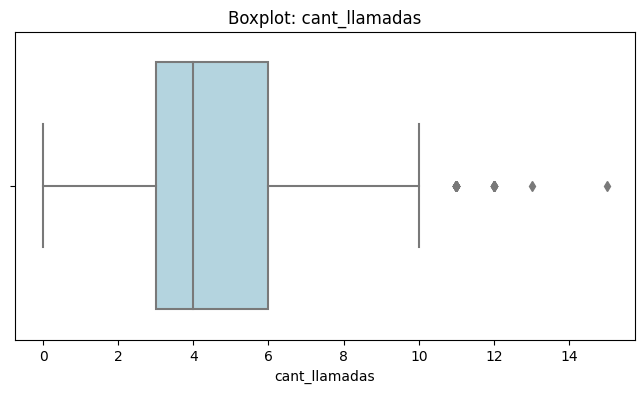

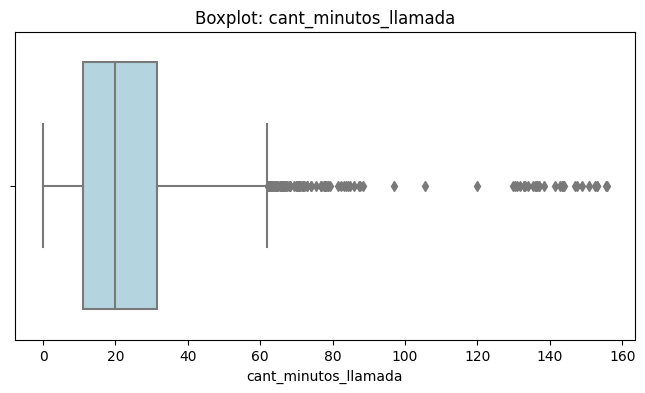

In [173]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col, color='lightblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Age:(presenta o no outliers) o presenta outliers; los valores se distribuyen de manera uniforme y simétrica dentro de los límites normales (desde los 18 hasta los 79 años).
- cant_mensajes: Sí presenta outliers leves en el extremo superior (valores que superan el límite superior del bigote, situados aproximadamente por encima de los 11-12 mensajes).
- cant_llamadas:Sí presenta outliers en el extremo superior (usuarios que realizan más de 10 u 11 llamadas, extendiéndose hasta un máximo de 15 llamadas). 
- cant_minutos_llamada: Sí presenta outliers claros en el extremo superior (valores altos de consumo en minutos que se extienden desde aproximadamente 62 minutos hasta un máximo de 155 minutos).

In [174]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

limites_superiores = {}
for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    limites_superiores[col] = limite_superior
    print(f"Límite superior para {col}: {limite_superior}")



Límite superior para cant_mensajes: 11.5
Límite superior para cant_llamadas: 10.5
Límite superior para cant_minutos_llamada: 61.8575


In [175]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?El límite superior calculado es 11.5 y el valor máximo registrado es de 17 mensajes, lo cual representa un comportamiento de consumo totalmente natural y dentro de los rangos esperados para la actividad de mensajería de un usuario.
- cant_llamadas: mantener o no outliers, porqué? El límite superior es de 10.5 y el valor máximo llega a 15 llamadas, una frecuencia perfectamente lógica y legítima que refleja un uso cotidiano o intensivo del servicio telefónico sin constituir una anomalía. 
- cant_minutos_llamada: mantener o no outliers, porqué? Aunque el límite superior es de 61.86 minutos y el máximo alcanza los 155.69 minutos, estos valores corresponden a clientes con un perfil de llamadas más largas (consumo intensivo), por lo que eliminarlos significaría descartar información real y valiosa de este segmento.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [181]:
# Crear columna grupo_uso
condiciones = [
    (user_profile["cant_llamadas"] < 5) & (user_profile["cant_mensajes"] < 5),
    (user_profile["cant_llamadas"] < 10) & (user_profile["cant_mensajes"] < 10)
]

resultados = ['Bajo uso', 'Uso medio']

user_profile["grupo_uso"] = np.select(condiciones, resultados, default='Alto uso')


In [182]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cyti,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Medellín,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,?,2022-01-01 06:34:17.914478619,Basico,NaN,<NA>,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,CDMX,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,Bogotá,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,GDL,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [183]:
# Crear columna grupo_edad
condiciones_edad = [
    (user_profile["age"] < 30),
    (user_profile["age"] < 60)
]
resultados_edad = ['Joven', 'Adulto']

user_profile["grupo_edad"] = np.select(condiciones_edad, resultados_edad, default='Adulto Mayor')

In [184]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cyti,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Medellín,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,?,2022-01-01 06:34:17.914478619,Basico,NaN,<NA>,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,CDMX,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,Bogotá,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,GDL,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

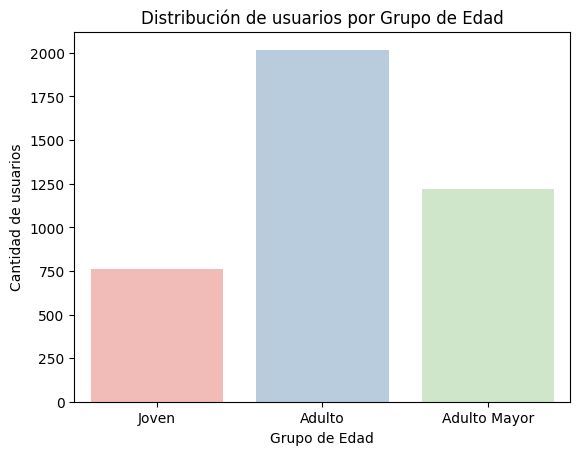

In [187]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x="grupo_edad", palette="Pastel1", order=['Joven', 'Adulto', 'Adulto Mayor'])
plt.title("Distribución de usuarios por Grupo de Edad")
plt.xlabel("Grupo de Edad")
plt.ylabel("Cantidad de usuarios")

plt.show()

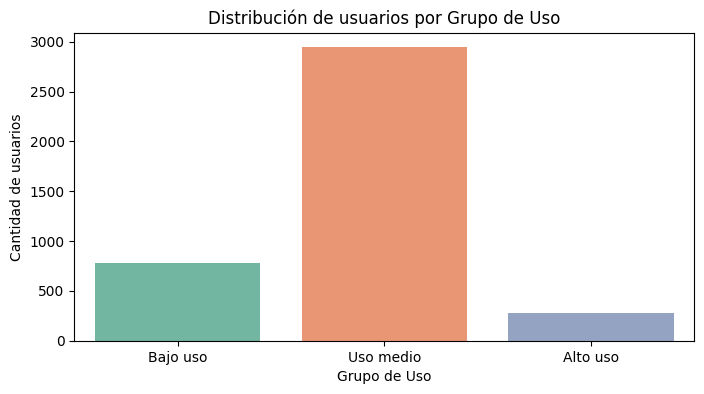

In [188]:

# Visualización de los segmentos por edad
plt.figure(figsize=(8, 4))
sns.countplot(data=user_profile, x="grupo_uso", palette="Set2", order=['Bajo uso', 'Uso medio', 'Alto uso'])
plt.title("Distribución de usuarios por Grupo de Uso")
plt.xlabel("Grupo de Uso")
plt.ylabel("Cantidad de usuarios")
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- abc
- abc
-Valores atípicos y sentinels: Se identificaron 55 registros con el valor -999 en la columna age (~1.38% de los datos), los cuales fueron imputados por la mediana para corregir el sesgo numérico.

Inconsistencias y nulos: La columna city presentó 469 valores nulos (~11.7%) y 96 registros con el símbolo ? (~2.4%), los cuales se estandarizaron como nulos. Asimismo, se detectaron 40 registros con fechas de registro futuras en el año 2026 (~1%), los cuales fueron descartados por inconsistencia temporal.

🔍 **Segmentos por Edad**
- abc
- abc 
- Distribución demográfica: Los clientes se concentran principalmente en los segmentos de Adultos (30 a 59 años) y Adultos Mayores (60 años o más), representando la mayor parte de la base de usuarios, con un grupo menor de usuarios Jóvenes (< 30 años).

Patrón transversal: La proporción de usuarios entre el plan Básico (~64.9%) y el Premium (~35.1%) se mantiene uniforme en todos los rangos de edad, sin evidenciar una preferencia generacional exclusiva por un tipo de plan.

📊 **Segmentos por Nivel de Uso**
- abc
- abc
- Clasificación de consumo: Al categorizar a los usuarios por su volumen de llamadas y mensajes, la gran mayoría se agrupa en niveles de Bajo uso y Uso medio, mientras que un segmento minoritario conforma el grupo de Alto uso.

Comportamiento equitativo: Al igual que en la edad, el nivel de uso no distingue drásticamente el tipo de plan contratado; tanto los clientes del plan Básico como del Premium comparten patrones de consumo cotidianos muy similares.

➡️ Esto sugiere que 
La oferta comercial actual no está diferenciando de manera efectiva el valor percibido por los clientes de mayor consumo frente a los de uso moderado o bajo, lo que representa una oportunidad latente para diseñar incentivos de migración y optimizar la monetización.


💡 **Recomendaciones**
- abc
- abc - Creación de planes o paquetes flexibles: Desarrollar un plan intermedio o complementos (add-ons) de minutos y mensajes para capturar mejor las necesidades del segmento de Alto uso que actualmente contrata planes básicos.

Estrategias de fidelización y retención: Implementar campañas focalizadas en los usuarios con mayor antigüedad y volumen de llamadas para prevenir la cancelación (churn) en clientes de alto valor.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`